In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random
from sklearn.metrics import accuracy_score, f1_score

import torch
from datasets import Dataset
from transformers import DistilBertTokenizerFast, DistilBertForSequenceClassification, Trainer, TrainingArguments

In [6]:
#loading prepared dataset

data_usefull = pd.read_csv("final_customer_sentiment_dataset.csv")
data_usefull.head()

,text,label
0,Erroneous image Don't be fooled by the carton...,0
1,Not gourmet Not gourmet by any stretch of the ...,0
2,showed more interest in a dust ball my cats lo...,0
3,real candy big pieces? I bought it and I was h...,0
4,Worst of all Timothy's K cups I have tried all...,0


In [7]:
#Load saved model and tokenizer 

MODEL_PATH = "sentiment_distilbert_best"

tokenizer = DistilBertTokenizerFast.from_pretrained(MODEL_PATH)
model = DistilBertForSequenceClassification.from_pretrained(MODEL_PATH)

In [9]:
#preparing test data 

df_test = data_usefull[["text", "label"]].copy()

In [10]:
#Assigining psudo domains 

domains = ["electronics", "books", "clothing", "home", "beauty"]

np.random.seed(42)
df_test["domain"] = np.random.choice(domains, size=len(df_test))

In [12]:
#convert to huggingface dataset

hf_test = Dataset.from_pandas(df_test)

In [14]:
#Tokenization

def tokenize(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        padding="max_length",
        max_length=256
    )

hf_test = hf_test.map(tokenize, batched=True)
hf_test.set_format(
    type="torch",
    columns=["input_ids", "attention_mask", "label"]
)

Map:   0%|          | 0/120000 [00:00<?, ? examples/s]

In [15]:
args = TrainingArguments(
    output_dir="./eval_only",
    per_device_eval_batch_size=16,
    report_to="none"
)

trainer = Trainer(
    model=model,
    args=args,
    tokenizer=tokenizer
)

In [16]:
domain_results = {}

for d in domains:
    domain_ds = hf_test.filter(lambda x: x["domain"] == d)

    preds = trainer.predict(domain_ds)
    y_pred = np.argmax(preds.predictions, axis=1)
    y_true = preds.label_ids

    domain_results[d] = {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred, average="macro"),
        "samples": len(domain_ds)
    }

df_drift = pd.DataFrame(domain_results).T
df_drift

Filter:   0%|          | 0/120000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/120000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/120000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/120000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/120000 [00:00<?, ? examples/s]

,accuracy,f1,samples
electronics,0.933423,0.933472,23912.0
books,0.933217,0.933505,24063.0
clothing,0.933074,0.933178,23683.0
home,0.933447,0.933647,24071.0
beauty,0.932677,0.932644,24271.0


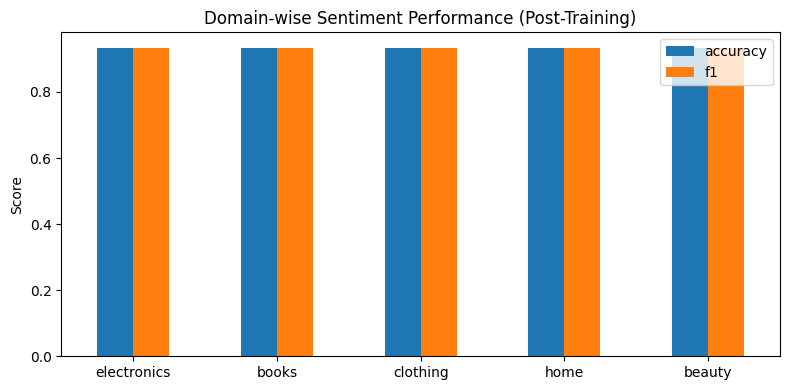

In [17]:
df_drift[["accuracy", "f1"]].plot(
    kind="bar",
    figsize=(8,4),
    title="Domain-wise Sentiment Performance (Post-Training)"
)

plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()